# Test 5: salida JSON estructurada

Se prueba si restringir la generación al esquema JSON evita las respuestas fuera de formato y si eso mejora la política de negociación. Se compara con las ejecuciones de 4.096 tokens del [Test 4](paired-search.ipynb).

**B1:** instrucciones de mejora fijas. **B2:** instrucciones adaptativas. Qwen3 8B a 4 bits, razonamiento activado, cinco intentos por condición. Sin entrenamiento ni API.

Los notebooks anteriores y sus resultados se conservan. Estas celdas leen evidencia guardada; ejecutarlas no llama al modelo.


In [1]:
from pathlib import Path
import hashlib
import html
import json
from collections import Counter
from IPython.display import display, HTML

case_dir = Path.cwd()
if not (case_dir / 'results').is_dir():
    case_dir /= 'research/cases/case-0003-debt-negotiation'
run_names = ['20261106T224117Z-paired-fixed-tokens-4096', '20261106T224923Z-paired-adaptive-tokens-4096', '20261106T231518Z-paired-fixed-tokens-4096-structured', '20261106T232337Z-paired-adaptive-tokens-4096-structured']
records = []
for name in run_names:
    folder = case_dir / 'results' / name
    for filename, digest in json.loads((folder / 'manifest.json').read_text()).items():
        assert Path(filename).name == filename
        assert hashlib.sha256((folder / filename).read_bytes()).hexdigest() == digest
    records.append({'name': name, 'protocol': json.loads((folder/'protocol.json').read_text()),
                    'report': json.loads((folder/'report.json').read_text()),
                    'calls': [json.loads(line) for line in (folder/'calls.jsonl').read_text().splitlines()]})
for item in records:
    for key in ('model', 'revision', 'model_files_sha256', 'sampling', 'limits', 'search_tokens',
                'final_tokens', 'cases', 'objective', 'initial_policy', 'initial_strategy',
                'runtime', 'proposal_contract', 'update_contract'):
        assert item['protocol'][key] == records[0]['protocol'][key], key
    for package, version in records[0]['protocol']['packages'].items():
        assert item['protocol']['packages'][package] == version, package
    for source in ('utils/harness_smoke_test.py', 'utils/prompt_search.py', 'paired-search-cases.yaml'):
        assert item['protocol']['source_hashes'][source] == records[0]['protocol']['source_hashes'][source], source
    assert item['report']['tokens'] == sum(c['input_tokens'] + c['output_tokens'] for c in item['calls'])
    assert item['report']['protected_source_changes'] == 0

def mode(item):
    return 'Restringido' if item['protocol'].get('decoding') == 'json_schema' else 'Solo prompt'

def condition(item):
    return 'B1 fija' if item['protocol']['strategy'] == 'fixed' else 'B2 adaptativa'

def table(headers, rows):
    style = 'text-align:left;vertical-align:top;padding:8px;border-bottom:1px solid #ddd;overflow-wrap:anywhere'
    header_style = style.replace('overflow-wrap:anywhere', 'overflow-wrap:normal;min-width:65px')
    head = ''.join(f'<th style="{header_style}">{html.escape(str(value))}</th>' for value in headers)
    body = ''.join('<tr>' + ''.join(f'<td style="{style}">{html.escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    display(HTML(f'<table style="width:100%;border-collapse:collapse"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'))

def block(title, text):
    display(HTML(f'<h4>{html.escape(title)}</h4><div style="white-space:pre-wrap;border-left:3px solid #526b82;padding:12px;background:#f6f8fa">{html.escape(text)}</div>'))
print(f'Evidencia verificada: {len(records)} ejecuciones. Sin llamadas al modelo.')


Evidencia verificada: 4 ejecuciones. Sin llamadas al modelo.


## 1. Qué cambia

En el Test 4 se pedía un JSON y se validaba después. Aquí, [LM Format Enforcer](https://github.com/noamgat/lm-format-enforcer) limita los tokens permitidos por el esquema mediante el [procesador de logits de MLX-LM](https://github.com/ml-explore/mlx-lm). Se activa después de `</think>`; el razonamiento sigue libre.

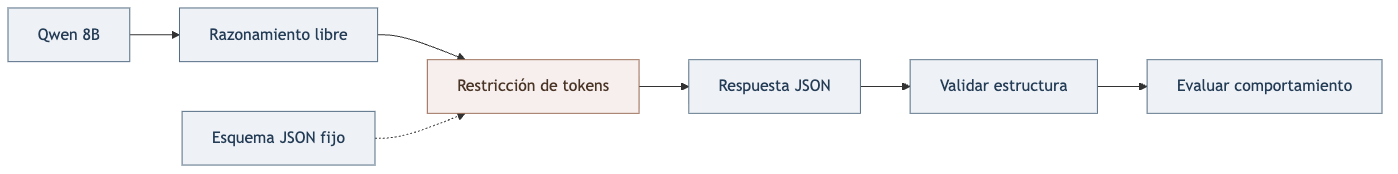

La misma restricción se aplica al negociador, al mejorador y al actualizador. Se fija antes de la búsqueda; el mejorador no puede editarla. Se conserva la validación posterior. No se reparan respuestas ni se reintentan llamadas. El esquema no contiene respuestas esperadas ni reglas para elegir la deuda. Restringir los tokens también puede cambiar el texto generado: no se repara una respuesta anterior.

| Control | Valor |
|---|---|
| Salida | Hasta 4.096 tokens, razonamiento incluido |
| Muestreo | Temperatura 0,6; top_p 0,95; top_k 20; semillas emparejadas por caso |
| Búsqueda | Cinco intentos; 120.000 tokens de búsqueda y hasta 60.000 para evaluación final |
| Parada | 90 llamadas o 1.800 segundos por condición; sin ampliar el presupuesto |
| Datos | Cuatro casos de desarrollo, cuatro de validación y ocho finales ya conocidos |

Los casos finales se reutilizan para este diagnóstico. No es una nueva confirmación. Los tiempos incluyen preparación de la gramática y no aíslan otras tareas de la laptop.


## 2. Estructura y calidad se miden por separado

- **Formato válido:** JSON completo que cumple los campos y tipos del esquema. No basta con poder leerlo como JSON.
- **Q:** decisiones correctas sin incumplimientos / casos evaluados.
- **V:** respuestas con algún incumplimiento / casos evaluados.

Se conserva una política si mejora Q en validación y V = 0. Los empates conservan la anterior. Una política con JSON correcto puede fallar al negociar.


In [2]:
rows = []
for item in records:
    report = item['report']; calls = item['calls']
    final = report.get('test', {}).get('selected')
    valid = sum(c.get('error') is None for c in calls)
    rows.append([mode(item), condition(item), f"{valid}/{len(calls)}",
                 f"{sum(r['success'] for r in final['rows'])}/{len(final['rows'])}" if final else 'Sin completar',
                 f"{final['v']:.0%}" if final else 'Sin completar',
                 report['selected_iteration'], report['tokens'], round(report['elapsed_seconds'])])
table(['Salida', 'Condición', 'Formato válido', 'Q final', 'V final', 'H seleccionada', 'Tokens totales', 'Segundos'], rows)
rows = []
for item in records:
    for role, title in [('negotiator', 'Negociador'), ('proposer', 'Mejorador'), ('strategy_update', 'Actualizador')]:
        calls = [c for c in item['calls'] if c['role'] == role]
        if not calls: continue
        errors = Counter(c['error'] for c in calls if c.get('error'))
        names = {'invalid_schema': 'fuera del esquema', 'invalid_json': 'JSON inválido', 'output_limit': 'corte'}
        rows.append([mode(item), condition(item), title, len(calls),
                     sum(bool(c.get('structured_generation', {}).get('activated')) for c in calls),
                     ', '.join(f"{names.get(k,k)}: {v}" for k,v in errors.items()) or 'Ninguno'])
table(['Salida', 'Condición', 'Papel', 'Llamadas', 'Restricción activada', 'Errores'], rows)
sample = next(c for c in records[2]['calls'] if c['role'] == 'proposer' and c.get('error') is None)
block('Ejemplo real · JSON del mejorador', json.dumps(sample['parsed'], ensure_ascii=False, indent=2))
before = records[1]['calls'][37]
after = records[3]['calls'][37]
assert before['role'] == after['role'] == 'strategy_update'
assert before['messages'] == after['messages']
assert before['raw_output'].split('</think>')[0] == after['raw_output'].split('</think>')[0]
table(['Actualizador B2 · llamada 38', 'Solo prompt', 'Restringido'],
      [['Estructura', before['error'], after['error'] or 'Válida'],
       ['Campo prompt en la raíz', 'No', 'Sí' if 'prompt' in after['parsed'] else 'No']])


Salida,Condición,Formato válido,Q final,V final,H seleccionada,Tokens totales,Segundos
Solo prompt,B1 fija,53/53,7/8,0%,2,68762,484
Solo prompt,B2 adaptativa,63/65,7/8,0%,1,84475,619
Restringido,B1 fija,53/53,7/8,0%,2,68762,497
Restringido,B2 adaptativa,73/73,7/8,0%,1,91579,664


Salida,Condición,Papel,Llamadas,Restricción activada,Errores
Solo prompt,B1 fija,Negociador,48,0,Ninguno
Solo prompt,B1 fija,Mejorador,5,0,Ninguno
Solo prompt,B2 adaptativa,Negociador,56,0,Ninguno
Solo prompt,B2 adaptativa,Mejorador,5,0,fuera del esquema: 1
Solo prompt,B2 adaptativa,Actualizador,4,0,fuera del esquema: 1
Restringido,B1 fija,Negociador,48,48,Ninguno
Restringido,B1 fija,Mejorador,5,5,Ninguno
Restringido,B2 adaptativa,Negociador,64,64,Ninguno
Restringido,B2 adaptativa,Mejorador,5,5,Ninguno
Restringido,B2 adaptativa,Actualizador,4,4,Ninguno


Actualizador B2 · llamada 38,Solo prompt,Restringido
Estructura,invalid_schema,Válida
Campo prompt en la raíz,No,Sí


## 3. Los cinco intentos

H es la política del negociador; φ son las instrucciones del mejorador. Se muestran las búsquedas nuevas. Las anteriores permanecen en el Test 4.


In [3]:
rows = []
for item in records[2:]:
    for row in item['report']['rounds']:
        rows.append([condition(item), row['iteration'],
                     f"{row['validation']['q']:.0%}" if 'validation' in row else 'Sin evaluar',
                     'Inicial' if row['iteration'] == 0 else 'Sí' if row['accepted'] else 'No',
                     row.get('error') or (f"Duplicada de {row['duplicate_of']}" if row.get('duplicate_of') is not None else '')])
table(['Condición', 'Propuesta', 'Q de la candidata: validación', 'Conservada', 'Observación'], rows)
for item in records[2:]:
    report = item['report']
    block(f"{condition(item)} · política seleccionada H{report['selected_iteration']}", report.get('selected_policy', 'Selección no completada'))
    if report['strategy_updates']:
        table(['Después de intento', 'Cambió φ', 'Reutilizada', 'Error'],
              [[u['after_iteration'], 'Sí' if u['changed'] else 'No',
                'Sí' if u['changed'] and any(r['iteration'] == u['after_iteration']+1 and r.get('strategy_used') == u['after'] for r in report['rounds']) else 'No',
                u['error'] or 'Ninguno'] for u in report['strategy_updates']])


Condición,Propuesta,Q de la candidata: validación,Conservada,Observación
B1 fija,0,0%,Inicial,
B1 fija,1,75%,Sí,
B1 fija,2,100%,Sí,
B1 fija,3,100%,No,Duplicada de 2
B1 fija,4,50%,No,
B1 fija,5,100%,No,Duplicada de 2
B2 adaptativa,0,0%,Inicial,
B2 adaptativa,1,75%,Sí,
B2 adaptativa,2,50%,No,
B2 adaptativa,3,75%,No,


Después de intento,Cambió φ,Reutilizada,Error
1,Sí,Sí,Ninguno
2,Sí,Sí,Ninguno
3,Sí,Sí,Ninguno
4,Sí,Sí,Ninguno


## 4. Respuestas finales

Se conserva la salida del modelo. El evaluador compara acción, deuda, pagos y cuota; la restricción de formato no elige esos valores por el modelo.


In [4]:
rows = []
for item in records[2:]:
    for row in item['report'].get('test', {}).get('selected', {}).get('rows', []):
        expected = ' / '.join(str(row['expected'][k]) for k in ('action', 'debt', 'payments', 'installment'))
        rows.append([condition(item), row['id'], expected, json.dumps(row['raw_reply'], ensure_ascii=False),
                     'Sí' if row['success'] else 'No', ', '.join(row['violations']) or 'Ninguno'])
table(['Condición', 'Caso', 'Esperado: acción/deuda/pagos/cuota', 'Respuesta', 'Correcta', 'Incumplimientos'], rows)


Condición,Caso,Esperado: acción/deuda/pagos/cuota,Respuesta,Correcta,Incumplimientos
B1 fija,paired-125,offer / A / 2 / 100,"{""action"": ""offer"", ""debt"": ""A"", ""payments"": 2, ""installment"": 100}",Sí,Ninguno
B1 fija,paired-225,offer / B / 2 / 150,"{""action"": ""offer"", ""debt"": ""A"", ""payments"": 1, ""installment"": 200}",No,Ninguno
B1 fija,paired-425,offer / C / 2 / 300,"{""action"": ""offer"", ""debt"": ""C"", ""payments"": 2, ""installment"": 300}",Sí,Ninguno
B1 fija,paired-725,offer / C / 1 / 600,"{""action"": ""offer"", ""debt"": ""C"", ""payments"": 1, ""installment"": 600}",Sí,Ninguno
B1 fija,paired-75,stop / None / 0 / 0,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,Ninguno
B1 fija,paired-unknown,ask / None / 0 / 0,"{""action"": ""ask"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,Ninguno
B1 fija,paired-decline,stop / None / 0 / 0,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,Ninguno
B1 fija,paired-consent,accept / B / 2 / 150,"{""action"": ""accept"", ""debt"": ""B"", ""payments"": 2, ""installment"": 150}",Sí,Ninguno
B2 adaptativa,paired-125,offer / A / 2 / 100,"{""action"": ""offer"", ""debt"": ""A"", ""payments"": 2, ""installment"": 100}",Sí,Ninguno
B2 adaptativa,paired-225,offer / B / 2 / 150,"{""action"": ""offer"", ""debt"": ""A"", ""payments"": 1, ""installment"": 200}",No,Ninguno


## 5. Lectura del resultado

- **Formato:** B1 produjo 53/53 respuestas válidas y B2, 73/73. En B2 desaparecieron los dos errores de esquema de la ejecución anterior (63/65).
- **Calidad final:** ambas condiciones conservaron 7/8 decisiones correctas (87,5 %), sin incumplimientos críticos. El resultado no aumentó con la restricción de formato.
- **Fallo pendiente:** con capacidad mensual de 225, ambas eligieron la deuda A en un pago de 200; correspondía B en dos cuotas de 150, la mayor deuda viable.
- **Adaptación:** las cuatro actualizaciones de instrucciones de B2 fueron válidas y se utilizaron en propuestas posteriores. No mejoraron la política seleccionada en el primer intento.

- **Consumo:** B1 usó 68.762 tokens y B2, 91.579. B2 hizo ocho llamadas más que antes porque su quinta propuesta pasó la validación de formato y pudo evaluarse en desarrollo y validación.

En la llamada 38 de B2, con la misma entrada y el mismo razonamiento, la salida pasó a cumplir el esquema. Sin embargo, la instrucción generada comparaba el total de pagos con la capacidad mensual, cuando debía comparar cada cuota. La actualización siguiente corrigió esa frase, pero no produjo una política mejor en validación. El formato quedó resuelto en esta prueba; la calidad de las propuestas sigue pendiente. Es una ejecución por condición sobre casos conocidos.

## 6. Evidencia y repetición

Cada ejecución conserva protocolo, llamadas, métricas, fuentes y hashes en `results/`. El adaptador solo cambia la generación. Para compilar el campo nullable `debt`, expresa el mismo conjunto permitido como unión de texto y `null`; la validación usa el esquema original. La gramática permite cualquier orden de campos y hasta 12 espacios consecutivos.

Con Python 3.12, [dependencias locales](requirements-local.txt) y los pesos fijados en caché:

```sh
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy fixed --output-tokens 4096 --decoding json_schema
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy adaptive --output-tokens 4096 --decoding json_schema
```

No se cambia la política manualmente durante las búsquedas. Una parada por presupuesto se registra; no se completa el JSON ni se corrige la decisión después.
